In [1]:
import pandas as pd

df = pd.read_csv("airfoil_results.csv")

df 

,angle_deg,drag_N,lift_N
0,9.000000,8.082660,-440.15311
1,12.000000,11.132633,-564.00591
2,9.612698,8.583996,-469.00440
3,0.491722,4.757995,-34.54773
4,5.447419,5.678937,-276.48497
5,3.688284,5.129142,-189.80843
6,17.764431,126.791650,-380.70574
7,18.413327,138.910190,-282.76277
8,11.647023,10.602333,-553.61105
9,15.333088,80.895000,-255.99000


# Task 2: Gaussian Process Modeling and Validation

## Prepare the model inputs

## Step 8: Load the 10 LHS runs

In [3]:
import pandas as pd
import numpy as np

# Step 8: Load the 10 LHS runs

df = pd.read_csv("airfoil_results.csv")

print("Rows:", len(df))

print("\nDuplicate angles:")
print(df[df.duplicated(subset=["angle_deg"], keep=False)])

print("\nMissing values:")
print(df.isnull().sum())

print("\nNonfinite values:")
print(~np.isfinite(df[["drag_N", "lift_N"]]).all())

df

Rows: 10

Duplicate angles:
Empty DataFrame
Columns: [angle_deg, drag_N, lift_N]
Index: []

Missing values:
angle_deg    0
drag_N       0
lift_N       0
dtype: int64

Nonfinite values:
drag_N    False
lift_N    False
dtype: bool


,angle_deg,drag_N,lift_N
0,9.000000,8.082660,-440.15311
1,12.000000,11.132633,-564.00591
2,9.612698,8.583996,-469.00440
3,0.491722,4.757995,-34.54773
4,5.447419,5.678937,-276.48497
5,3.688284,5.129142,-189.80843
6,17.764431,126.791650,-380.70574
7,18.413327,138.910190,-282.76277
8,11.647023,10.602333,-553.61105
9,15.333088,80.895000,-255.99000


### Step 8 Discussion:  

The CFD dataset was loaded from airfoil_results.csv and checked for duplicate angles, missing values, and nonfinite force values. No duplicate angles were found. No missing values were present in any column, and all drag and lift force values were finite. Drag was measured in the positive x-direction and lift was measured in the positive y-direction, with both forces reported in newtons.

## Step 9: Downforce and Drag-to-Downforce Ratio

In [ ]:
# Step 9: Downforce and Drag-to-Downforce Ratio

import numpy as np

df["drag_to_downforce"] = np.where(
    -df["lift_N"] >= 50,
    df["drag_N"] / (-df["lift_N"]),
    np.nan
)

df = df.sort_values("angle_deg").reset_index(drop=True)

df[["angle_deg", "drag_N", "lift_N", "drag_to_downforce"]].to_csv(
    "cvanvoor_pr04_cfd.csv",
    index=False
)

df[["angle_deg", "drag_N", "lift_N", "drag_to_downforce"]]

,angle_deg,drag_N,lift_N,drag_to_downforce
0,0.491722,4.757995,-34.54773,NaN
1,3.688284,5.129142,-189.80843,0.027023
2,5.447419,5.678937,-276.48497,0.020540
3,9.000000,8.082660,-440.15311,0.018363
4,9.612698,8.583996,-469.00440,0.018303
5,11.647023,10.602333,-553.61105,0.019151
6,12.000000,11.132633,-564.00591,0.019739
7,15.333088,80.895000,-255.99000,0.316008
8,17.764431,126.791650,-380.70574,0.333044
9,18.413327,138.910190,-282.76277,0.491261


### Step 9 Discussion:  

Downforce was calculated as the negative of lift. A minimum downforce threshold of 50 N was used when computing the drag-to-downforce ratio. Below this threshold, small changes in downforce can cause large changes in the ratio, making it less meaningful for comparison. Drag and lift values were retained for all runs. The dataset was sorted by angle and saved as cvanvoor_pr04_cfd.csv.

## Evaluate predictions on three held out runs 

## Step 10 - Training and Test Data Spilt

In [6]:
# Step 10: Training and Test Data Split

import pandas as pd

df = pd.read_csv("cvanvoor_pr04_cfd.csv")

df = df.sort_values("angle_deg").reset_index(drop=True)

test_rows = [2, 5, 8]  # 3rd, 6th, and 9th rows

test = df.iloc[test_rows]
train = df.drop(index=test_rows)

print("Number of training runs:", len(train))
print("Number of test runs:", len(test))

train


Number of training runs: 7
Number of test runs: 3


,angle_deg,drag_N,lift_N,drag_to_downforce
0,0.491722,4.757995,-34.54773,NaN
1,3.688284,5.129142,-189.80843,0.027023
3,9.000000,8.082660,-440.15311,0.018363
4,9.612698,8.583996,-469.00440,0.018303
6,12.000000,11.132633,-564.00591,0.019739
7,15.333088,80.895000,-255.99000,0.316008
9,18.413327,138.910190,-282.76277,0.491261


In [7]:
test

,angle_deg,drag_N,lift_N,drag_to_downforce
2,5.447419,5.678937,-276.48497,0.020540
5,11.647023,10.602333,-553.61105,0.019151
8,17.764431,126.791650,-380.70574,0.333044


### Step 10 Discussion: 

After sorting the CFD results by angle, the 3rd, 6th, and 9th runs were reserved for testing as required by the assignment. The remaining seven runs were used for training. The same split was used for both the drag and lift Gaussian Process models.

## Step 11 - Gaussian Process Model Training

In [9]:
# Step 11: Gaussian Process Model Training

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

X_train = train[["angle_deg"]]

gp_drag = GaussianProcessRegressor(
    kernel=ConstantKernel() * RBF(),
    normalize_y=True
)

gp_lift = GaussianProcessRegressor(
    kernel=ConstantKernel() * RBF(),
    normalize_y=True
)

gp_drag.fit(X_train, train["drag_N"])
gp_lift.fit(X_train, train["lift_N"])

for name, model in [("Drag", gp_drag), ("Lift", gp_lift)]:
    print(name)
    print("Fitted kernel:", model.kernel_)
    print("Kernel variance:", model.kernel_.k1.constant_value)
    print("Length scale (deg):", model.kernel_.k2.length_scale)
    print()

Drag
Fitted kernel: 1.03**2 * RBF(length_scale=3.57)
Kernel variance: 1.0546362524453405
Length scale (deg): 3.569426297740479

Lift
Fitted kernel: 0.969**2 * RBF(length_scale=2.43)
Kernel variance: 0.9388262056138242
Length scale (deg): 2.4275497376634396



### Step 11 Discussion: 

Separate Gaussian Process Regression models were trained for drag and lift using angle as the only input variable. Both models used a ConstantKernel multiplied by an RBF kernel with normalize_y=True. The drag model converged to a kernel variance of 1.0546 and a length scale of 3.5694°. The lift model converged to a kernel variance of 0.9388 and a length scale of 2.4275°. The shorter length scale for lift indicates that lift changes more rapidly with angle than drag over the sampled range.

## Step 12 - Prediction and Residual Calculation

In [10]:
# Step 12: Prediction and Residual Calculation

X_test = test[["angle_deg"]]

test = test.copy()

test["predicted_drag_N"] = gp_drag.predict(X_test)
test["predicted_lift_N"] = gp_lift.predict(X_test)

test["drag_residual_N"] = (
    test["drag_N"] - test["predicted_drag_N"]
)

test["lift_residual_N"] = (
    test["lift_N"] - test["predicted_lift_N"]
)

test[
    [
        "angle_deg",
        "drag_N",
        "predicted_drag_N",
        "drag_residual_N",
        "lift_N",
        "predicted_lift_N",
        "lift_residual_N",
    ]
]

,angle_deg,drag_N,predicted_drag_N,drag_residual_N,lift_N,predicted_lift_N,lift_residual_N
2,5.447419,5.678937,1.315408,4.363529,-276.48497,-313.731219,37.246249
5,11.647023,10.602333,9.425830,1.176503,-553.61105,-564.671907,11.060857
8,17.764431,126.791650,135.481759,-8.690109,-380.70574,-250.921318,-129.784422


### Step 12 Discussion:  

The drag and lift Gaussian Process models were used to predict the forces at the three held-out test angles. Residuals were calculated as observed minus predicted values for both drag and lift.

## Step 13 - Test RSME and Prediction Table

In [11]:
# Step 13: Test RMSE and Prediction Table

from sklearn.metrics import mean_squared_error
from math import sqrt

drag_rmse = sqrt(
    mean_squared_error(
        test["drag_N"],
        test["predicted_drag_N"]
    )
)

lift_rmse = sqrt(
    mean_squared_error(
        test["lift_N"],
        test["predicted_lift_N"]
    )
)

print(f"Drag RMSE: {drag_rmse:.4f} N")
print(f"Lift RMSE: {lift_rmse:.4f} N")

results_table = test[
    [
        "angle_deg",
        "drag_N",
        "predicted_drag_N",
        "drag_residual_N",
        "lift_N",
        "predicted_lift_N",
        "lift_residual_N",
    ]
]

results_table

Drag RMSE: 5.6552 N
Lift RMSE: 78.2168 N


,angle_deg,drag_N,predicted_drag_N,drag_residual_N,lift_N,predicted_lift_N,lift_residual_N
2,5.447419,5.678937,1.315408,4.363529,-276.48497,-313.731219,37.246249
5,11.647023,10.602333,9.425830,1.176503,-553.61105,-564.671907,11.060857
8,17.764431,126.791650,135.481759,-8.690109,-380.70574,-250.921318,-129.784422


### Step 13 Discussion: 

The Gaussian Process models were evaluated using the three held-out test runs. The drag model achieved a test RMSE of 5.6552 N, while the lift model achieved a test RMSE of 78.2168 N. The larger lift RMSE indicates that lift was more difficult to predict than drag over the sampled angle range. The table below compares the observed CFD forces with the GP predictions and reports the residuals calculated as observed minus predicted.

## Step 14 - Observed vs Predicted Comparison

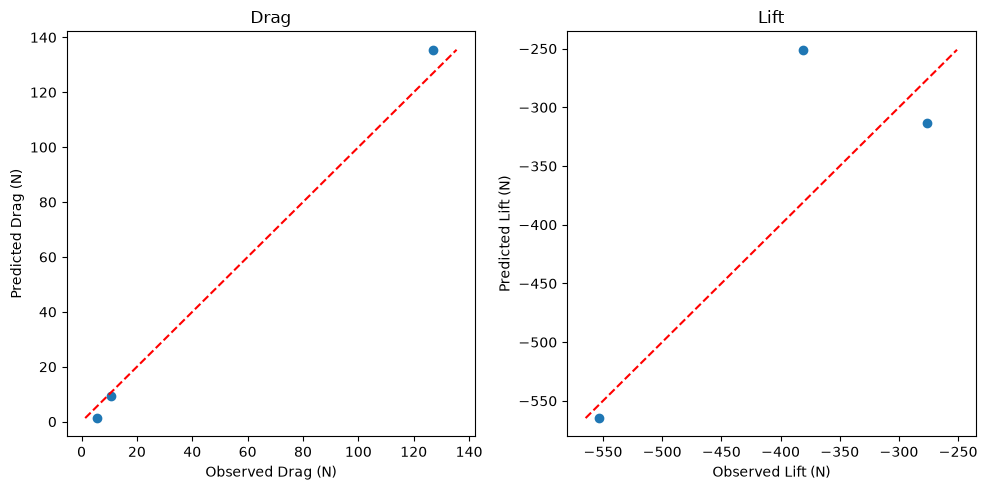

In [12]:
# Step 14: Observed vs Predicted Comparison

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Drag plot
axes[0].scatter(
    test["drag_N"],
    test["predicted_drag_N"]
)

drag_min = min(
    test["drag_N"].min(),
    test["predicted_drag_N"].min()
)

drag_max = max(
    test["drag_N"].max(),
    test["predicted_drag_N"].max()
)

axes[0].plot(
    [drag_min, drag_max],
    [drag_min, drag_max],
    "r--"
)

axes[0].set_title("Drag")
axes[0].set_xlabel("Observed Drag (N)")
axes[0].set_ylabel("Predicted Drag (N)")

# Lift plot
axes[1].scatter(
    test["lift_N"],
    test["predicted_lift_N"]
)

lift_min = min(
    test["lift_N"].min(),
    test["predicted_lift_N"].min()
)

lift_max = max(
    test["lift_N"].max(),
    test["predicted_lift_N"].max()
)

axes[1].plot(
    [lift_min, lift_max],
    [lift_min, lift_max],
    "r--"
)

axes[1].set_title("Lift")
axes[1].set_xlabel("Observed Lift (N)")
axes[1].set_ylabel("Predicted Lift (N)")

plt.tight_layout()
plt.show()

In [13]:
# Step 14: Observed vs Predicted Comparison

drag_max_error_row = test.loc[
    test["drag_residual_N"].abs().idxmax()
]

lift_max_error_row = test.loc[
    test["lift_residual_N"].abs().idxmax()
]

print("Largest drag error:")
display(drag_max_error_row)

print("Largest lift error:")
display(lift_max_error_row)

Largest drag error:


angle_deg             17.764431
drag_N               126.791650
lift_N              -380.705740
drag_to_downforce      0.333044
predicted_drag_N     135.481759
predicted_lift_N    -250.921318
drag_residual_N       -8.690109
lift_residual_N     -129.784422
Name: 8, dtype: float64

Largest lift error:


angle_deg             17.764431
drag_N               126.791650
lift_N              -380.705740
drag_to_downforce      0.333044
predicted_drag_N     135.481759
predicted_lift_N    -250.921318
drag_residual_N       -8.690109
lift_residual_N     -129.784422
Name: 8, dtype: float64

### Step 14 Discussion:  

The observed-versus-predicted plots show that the Gaussian Process models generally follow the CFD results, with most points lying reasonably close to the y=x line. The largest absolute drag error and the largest absolute lift error both occurred at a wing angle of 17.764°. At this angle, the drag residual was -8.690 N and the lift residual was -129.784 N. The larger lift error suggests that the lift response becomes more difficult to model accurately at higher wing angles. When selecting a wing angle using a surrogate model, these prediction errors should be considered because the predicted aerodynamic forces may differ from the CFD results. Larger errors may indicate regions where additional CFD samples would improve the accuracy of the Gaussian Process model.

## Refit and visualize the final GPs

## Step 15 - Refit Gaussian Process Models Using All CFD Runs

In [14]:
# Step 15: Refit Gaussian Process Models Using All CFD Runs

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
import numpy as np

X_all = df[["angle_deg"]]

gp_drag_final = GaussianProcessRegressor(
    kernel=ConstantKernel() * RBF(),
    normalize_y=True
)

gp_lift_final = GaussianProcessRegressor(
    kernel=ConstantKernel() * RBF(),
    normalize_y=True
)

gp_drag_final.fit(X_all, df["drag_N"])
gp_lift_final.fit(X_all, df["lift_N"])

print("Drag GP")
print("Fitted kernel:", gp_drag_final.kernel_)
print("Kernel variance:", gp_drag_final.kernel_.k1.constant_value)
print("Length scale (deg):", gp_drag_final.kernel_.k2.length_scale)

print()

print("Lift GP")
print("Fitted kernel:", gp_lift_final.kernel_)
print("Kernel variance:", gp_lift_final.kernel_.k1.constant_value)
print("Length scale (deg):", gp_lift_final.kernel_.k2.length_scale)


Drag GP
Fitted kernel: 0.927**2 * RBF(length_scale=2.38)
Kernel variance: 0.8598805883826004
Length scale (deg): 2.378569565721292

Lift GP
Fitted kernel: 1.03**2 * RBF(length_scale=1.49)
Kernel variance: 1.0565498592460918
Length scale (deg): 1.4907767445132885


In [16]:
# Step 15: Refit Gaussian Process Models Using All CFD Runs

# Step 15: Create the Prediction Grid

X_grid = pd.DataFrame({
    "angle_deg": np.linspace(
        df["angle_deg"].min(),
        df["angle_deg"].max(),
        200
    )
})

drag_mean, drag_std = gp_drag_final.predict(
    X_grid,
    return_std=True
)

lift_mean, lift_std = gp_lift_final.predict(
    X_grid,
    return_std=True
)

drag_variance = drag_std**2
lift_variance = lift_std**2

### Step 15 Discussion:

The Gaussian Process models were refit using all ten CFD simulations. The drag model produced a kernel variance of 0.8599 and a length scale of 2.3786°. The lift model produced a kernel variance of 1.0565 and a length scale of 1.4908°. The smaller lift length scale indicates that lift changes more rapidly with angle than drag, requiring a shorter correlation distance to accurately represent the response.

## Step 16 - Final Gaussian Process Visualization and Predictive Variance

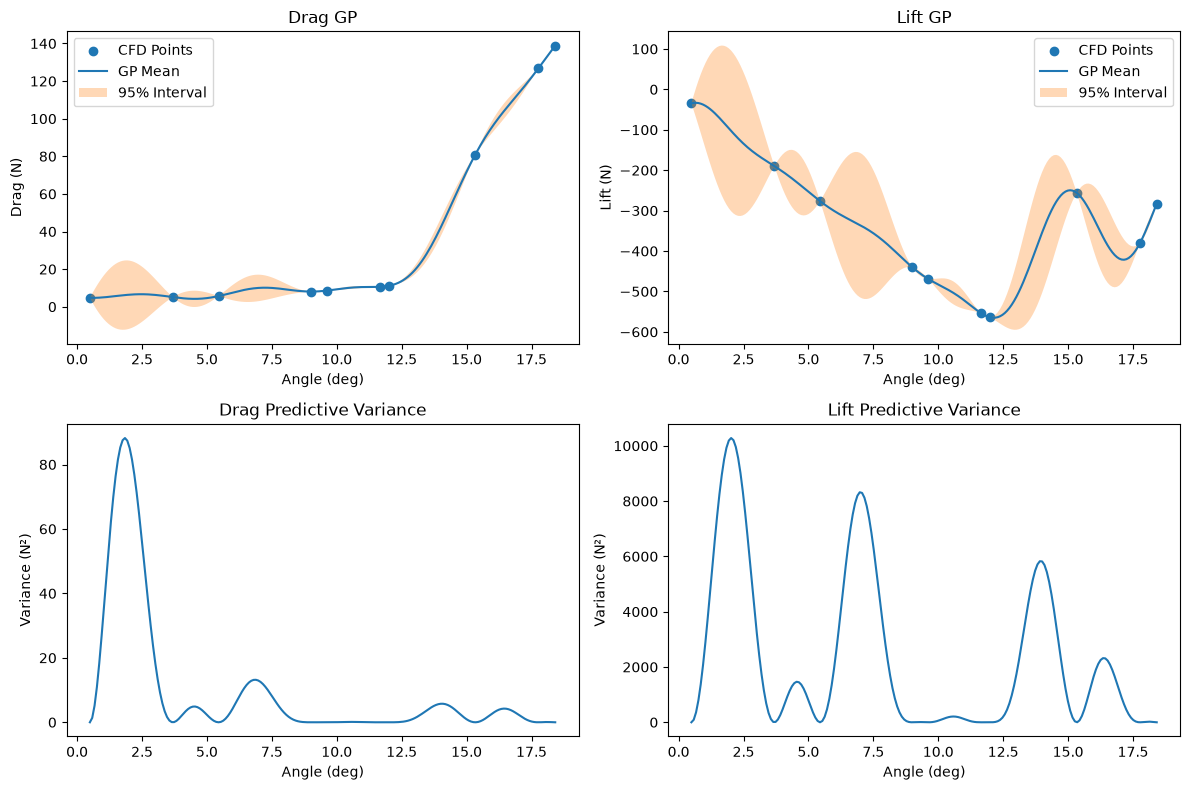

In [17]:
# Step 16: Final Gaussian Process Visualization and Predictive Variance

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# -------------------
# Drag mean plot
# -------------------
axes[0, 0].scatter(
    df["angle_deg"],
    df["drag_N"],
    label="CFD Points"
)

axes[0, 0].plot(
    X_grid["angle_deg"],
    drag_mean,
    label="GP Mean"
)

axes[0, 0].fill_between(
    X_grid["angle_deg"],
    drag_mean - 1.96 * drag_std,
    drag_mean + 1.96 * drag_std,
    alpha=0.3,
    label="95% Interval"
)

axes[0, 0].set_title("Drag GP")
axes[0, 0].set_xlabel("Angle (deg)")
axes[0, 0].set_ylabel("Drag (N)")
axes[0, 0].legend()

# -------------------
# Lift mean plot
# -------------------
axes[0, 1].scatter(
    df["angle_deg"],
    df["lift_N"],
    label="CFD Points"
)

axes[0, 1].plot(
    X_grid["angle_deg"],
    lift_mean,
    label="GP Mean"
)

axes[0, 1].fill_between(
    X_grid["angle_deg"],
    lift_mean - 1.96 * lift_std,
    lift_mean + 1.96 * lift_std,
    alpha=0.3,
    label="95% Interval"
)

axes[0, 1].set_title("Lift GP")
axes[0, 1].set_xlabel("Angle (deg)")
axes[0, 1].set_ylabel("Lift (N)")
axes[0, 1].legend()

# -------------------
# Drag variance
# -------------------
axes[1, 0].plot(
    X_grid["angle_deg"],
    drag_variance
)

axes[1, 0].set_title("Drag Predictive Variance")
axes[1, 0].set_xlabel("Angle (deg)")
axes[1, 0].set_ylabel("Variance (N²)")

# -------------------
# Lift variance
# -------------------
axes[1, 1].plot(
    X_grid["angle_deg"],
    lift_variance
)

axes[1, 1].set_title("Lift Predictive Variance")
axes[1, 1].set_xlabel("Angle (deg)")
axes[1, 1].set_ylabel("Variance (N²)")

plt.tight_layout()
plt.show()

In [18]:
# Step 16: Final Gaussian Process Visualization and Predictive Variance

# Step 16: Find Maximum Predictive Variance

drag_max_var_idx = np.argmax(drag_variance)
lift_max_var_idx = np.argmax(lift_variance)

drag_max_var_angle = X_grid.iloc[drag_max_var_idx, 0]
lift_max_var_angle = X_grid.iloc[lift_max_var_idx, 0]

print("Drag maximum variance angle:", drag_max_var_angle)
print("Lift maximum variance angle:", lift_max_var_angle)

print("Maximum drag variance:", drag_variance[drag_max_var_idx])
print("Maximum lift variance:", lift_variance[lift_max_var_idx])

Drag maximum variance angle: 1.8425968373752524
Lift maximum variance angle: 2.022713473566406
Maximum drag variance: 88.21146896076121
Maximum lift variance: 10280.144325010539


### Step 16 Discussion: 

The top row of the figure shows the CFD data, Gaussian Process predictive mean, and the 95% confidence interval defined by the predictive mean ±1.96 standard deviations. The bottom row shows the predictive variance, which is the square of the predictive standard deviation.

The highest predictive variance for drag occurred at approximately 1.843° with a variance of 88.21 N². The highest predictive variance for lift occurred at approximately 2.023° with a variance of 10,280.14 N². Predictive variance measures the model's uncertainty in its predictions. Regions with higher variance indicate lower confidence in the predicted values and suggest that additional CFD samples in those regions could improve model accuracy.

Mesh size can affect CFD results because coarse meshes may not adequately capture important flow features around the airfoil, leading to numerical errors in drag and lift predictions. Convergence quality can also affect results because insufficiently converged solutions may produce inaccurate aerodynamic forces. Turbulence modeling introduces additional uncertainty because turbulence models approximate complex flow physics and may not perfectly represent real aerodynamic behavior, particularly at higher angles of attack.

# Task 3:  Engineering Recommendation 

## Step 17 - Engineering Recommendation

In [19]:
# Step 17: Engineering Recommendation

grid_results = pd.DataFrame({
    "angle_deg": X_grid["angle_deg"],
    "predicted_drag_N": drag_mean,
    "predicted_lift_N": lift_mean
})

grid_results["predicted_downforce_N"] = (
    -grid_results["predicted_lift_N"]
)

grid_results["drag_to_downforce"] = np.where(
    grid_results["predicted_downforce_N"] >= 50,
    grid_results["predicted_drag_N"]
    / grid_results["predicted_downforce_N"],
    np.nan
)

best_grid_row = grid_results.loc[
    grid_results["drag_to_downforce"].idxmin()
]

best_grid_row

angle_deg                  4.814521
predicted_drag_N           4.344982
predicted_lift_N        -243.500728
predicted_downforce_N    243.500728
drag_to_downforce          0.017844
Name: 48, dtype: float64

In [20]:
# Step 17: Engineering Recommendation 

# Step 17: Find Best Sampled CFD Point

observed = df.copy()

observed["downforce_N"] = -observed["lift_N"]

observed["drag_to_downforce"] = np.where(
    observed["downforce_N"] >= 50,
    observed["drag_N"] / observed["downforce_N"],
    np.nan
)

best_observed_row = observed.loc[
    observed["drag_to_downforce"].idxmin()
]

best_observed_row

angle_deg              9.612698
drag_N                 8.583996
lift_N              -469.004400
drag_to_downforce      0.018303
downforce_N          469.004400
Name: 4, dtype: float64

### Step 17 Discussion:

The drag-to-downforce ratio was calculated using the Gaussian Process predictive means. The same minimum downforce threshold of 50 N used previously was applied when computing the ratio. Among all eligible grid points, the minimum predicted drag-to-downforce ratio occurred at a wing angle of approximately 4.815°. At this angle, the model predicted a drag force of 4.345 N, a downforce of 243.501 N, and a drag-to-downforce ratio of 0.01784.

The best observed CFD case occurred at an angle of 9.613°, which produced 8.584 N of drag, 469.004 N of downforce, and a drag-to-downforce ratio of 0.01830. The predicted optimum ratio is slightly lower than the best observed ratio, indicating that the Gaussian Process model identified a potentially better operating point between the sampled CFD angles.

The recommended angle does not lie at the boundary of the sampled angle range, suggesting that the optimum is located inside the design space rather than at one of its limits.

## Step 18: Follow-Up Simulation Recommendation

A follow-up CFD simulation is recommended near 2° of wing angle. The drag model exhibited its highest predictive variance at approximately 1.843°, while the lift model exhibited its highest predictive variance at approximately 2.023°. Because predictive variance measures model uncertainty, additional CFD data in this region would help improve the accuracy of the Gaussian Process models.

The test results also demonstrated prediction error, particularly for lift, which produced a test RMSE of 78.217 N. Collecting another CFD sample in a high-uncertainty region would help reduce uncertainty and improve future predictions.

Although the lowest predicted drag-to-downforce ratio occurred near 4.815°, ratio alone provides limited information about aerodynamic performance. A very low ratio can occur when both drag and downforce are small. In practice, the absolute amount of downforce is important because it directly affects tire grip and vehicle performance. Therefore, wing-angle selection should consider both the drag-to-downforce ratio and the total downforce available to the car.

## Step 19 - Fluent Verification Recommendation

A follow-up Fluent simulation is recommended at approximately 2° of wing angle. This region was selected because both the drag and lift Gaussian Process models exhibited their highest predictive variance near 2°, indicating that the models have the greatest uncertainty in this area. Additional CFD data at this angle would help improve confidence in the surrogate model predictions.

To verify the Gaussian Process predictions, a new Fluent simulation would be performed at the recommended angle. The resulting drag force, lift force, and drag-to-downforce ratio would be compared directly with the corresponding Gaussian Process predictions. The prediction error could be evaluated by calculating the difference between the CFD results and the predicted values. If the errors are small relative to the previously observed test RMSE values (5.66 N for drag and 78.22 N for lift), the Gaussian Process models would be considered reasonably accurate in this region.

The drag-to-downforce ratio from the verification run would also be compared to the predicted optimum ratio identified in Step 17. This comparison would help determine whether the recommended angle actually provides improved aerodynamic efficiency when evaluated using CFD.

One limitation of using a two-dimensional wing section is that it does not capture three-dimensional aerodynamic effects that occur on a real race car. Effects such as wingtip vortices, spanwise flow, endplate interactions, and interactions with the vehicle body are neglected in a 2D simulation. As a result, the aerodynamic forces predicted by the 2D model may differ from the forces generated by a full vehicle operating on track.